# Missing Data

In [1]:
from pathlib import Path
import pandas as pd

notebook_dir = Path.cwd()
raw_dir = notebook_dir.parent / 'src' / 'data' / 'raw'
train_path = raw_dir / 'train.csv'
test_path = raw_dir / 'test.csv'

In [4]:
def load_csv(path: Path) -> pd.DataFrame:
    return pd.read_csv(path)


def missing_report(df: pd.DataFrame) -> pd.DataFrame:
    missing_mask = df.isna()

    obj_cols = df.select_dtypes(include='object').columns
    blank_mask = pd.DataFrame(False, index=df.index, columns=df.columns)
    for col in obj_cols:
        blank_mask[col] = df[col].notna() & df[col].astype(str).str.strip().eq('')

    missing_count = missing_mask.sum()
    blank_count = blank_mask.sum()
    total_count = missing_count + blank_count

    report = pd.DataFrame({
        'missing_count': missing_count,
        'missing_pct': missing_mask.mean() * 100,
        'blank_count': blank_count,
        'blank_pct': blank_mask.mean() * 100,
        'missing_or_blank_pct': total_count / len(df) * 100,
        'dtype': df.dtypes,
    })
    return report.sort_values('missing_or_blank_pct', ascending=False)

train_df = load_csv(train_path)
test_df = load_csv(test_path)

train_report = missing_report(train_df)
test_report = missing_report(test_df)

print('\nTrain missing data report:')
print(train_report.to_string())

print('\nTest missing data report:')
print(test_report.to_string())


Train missing data report:
                      missing_count  missing_pct  blank_count  blank_pct  missing_or_blank_pct    dtype
transaction_id                    0          0.0            0        0.0                   0.0    int64
user_id                           0          0.0            0        0.0                   0.0    int64
timestamp                         0          0.0            0        0.0                   0.0    int64
amount                            0          0.0            0        0.0                   0.0  float64
merchant_category                 0          0.0            0        0.0                   0.0    int64
country                           0          0.0            0        0.0                   0.0    int64
device_id                         0          0.0            0        0.0                   0.0    int64
channel                           0          0.0            0        0.0                   0.0    int64
hours_since_prev_txn              0 

In [5]:

print(train_df.shape, test_df.shape)
print(train_df["label"].mean())                 # fraud rate — expect something small, e.g. 1–5%
print(train_df.groupby("user_id").size().describe())   # transactions per user
print(train_df["timestamp"].min(), train_df["timestamp"].max())
print(test_df["timestamp"].min(),  test_df["timestamp"].max())

(182125, 10) (45531, 9)
0.016417295813315032
count    5000.000000
mean       36.425000
std         5.956431
min        18.000000
25%        32.000000
50%        36.000000
75%        40.000000
max        60.000000
dtype: float64
6 2874525
70 2874525


In [6]:
print('Train unique user_ids:', train_df['user_id'].nunique())
print('Test unique user_ids:', test_df['user_id'].nunique())


Train unique user_ids: 5000
Test unique user_ids: 5000


In [7]:
print('Train timestamp min/max:', train_df['timestamp'].min(), train_df['timestamp'].max())
print('Test timestamp min/max:', test_df['timestamp'].min(), test_df['timestamp'].max())

Train timestamp min/max: 6 2874525
Test timestamp min/max: 70 2874525


In [8]:
train_users = set(train_df['user_id'].unique())
test_users = set(test_df['user_id'].unique())

overlap_users = train_users & test_users
only_train = train_users - test_users
only_test = test_users - train_users

print('Train unique users:', len(train_users))
print('Test unique users:', len(test_users))
print('Users in both train and test:', len(overlap_users))
print('Users only in train:', len(only_train))
print('Users only in test:', len(only_test))
print('Pct of train users also in test: {:.2f}%'.format(100 * len(overlap_users) / len(train_users)))

Train unique users: 5000
Test unique users: 5000
Users in both train and test: 5000
Users only in train: 0
Users only in test: 0
Pct of train users also in test: 100.00%


In [9]:
### Timestamp overlap between train and test, per user

train_ts = train_df.groupby('user_id')['timestamp'].agg(['min', 'max'])
test_ts = test_df.groupby('user_id')['timestamp'].agg(['min', 'max'])

ts_cmp = train_ts.join(test_ts, how='inner', lsuffix='_train', rsuffix='_test')

# Range overlap: the [min,max] timestamp window in train intersects the window in test
range_overlap = (ts_cmp['min_train'] <= ts_cmp['max_test']) & (ts_cmp['min_test'] <= ts_cmp['max_train'])

# Exact timestamp overlap: same user has at least one identical timestamp value in both train and test
train_ts_sets = train_df.groupby('user_id')['timestamp'].apply(set)
test_ts_sets = test_df.groupby('user_id')['timestamp'].apply(set)
common_users = ts_cmp.index
exact_overlap = pd.Series(
    [bool(train_ts_sets[u] & test_ts_sets[u]) for u in common_users],
    index=common_users,
)

print('Users present in both train and test:', len(ts_cmp))
print('Users whose train/test timestamp RANGES overlap:', range_overlap.sum(),
      '({:.2f}%)'.format(100 * range_overlap.mean()))
print('Users with at least one EXACT identical timestamp in train and test:', exact_overlap.sum(),
      '({:.2f}%)'.format(100 * exact_overlap.mean()))

# Sanity check: for users without range overlap, is test always after train (temporal holdout)?
test_after_train = ts_cmp.loc[~range_overlap, 'min_test'] > ts_cmp.loc[~range_overlap, 'max_train']
print('Of non-overlapping users, test entirely after train:', test_after_train.sum(), '/', (~range_overlap).sum())


Users present in both train and test: 5000
Users whose train/test timestamp RANGES overlap: 4999 (99.98%)
Users with at least one EXACT identical timestamp in train and test: 1 (0.02%)
Of non-overlapping users, test entirely after train: 0 / 1


In [10]:
### Per user: is train max timestamp < test min timestamp (clean temporal split)?

clean_split = ts_cmp['max_train'] < ts_cmp['min_test']

print('Users with train.max < test.min:', clean_split.sum(), '/', len(ts_cmp),
      '({:.2f}%)'.format(100 * clean_split.mean()))
print('Users where train and test timestamps interleave/violate this:', (~clean_split).sum())

ts_cmp.loc[~clean_split].head()


Users with train.max < test.min: 0 / 5000 (0.00%)
Users where train and test timestamps interleave/violate this: 5000


,min_train,max_train,min_test,max_test
user_id,,,,
0,10592,2826400,105635,2843152
1,53908,2871885,633208,2666363
2,10211,2727828,309372,2656513
3,263496,2807023,115167,2408001
4,81915,2873019,890256,2120229


In [11]:
### Merge train and test into a single combined.csv

combined_df = pd.concat(
    [train_df.assign(dataset='train'), test_df.assign(dataset='test')],
    ignore_index=True,
)

combined_path = raw_dir.parent / 'processed' / 'combined.csv'
combined_path.parent.mkdir(parents=True, exist_ok=True)
combined_df.to_csv(combined_path, index=False)

print('Combined shape:', combined_df.shape)
print('Saved to:', combined_path)
combined_df['dataset'].value_counts()


Combined shape: (227656, 11)
Saved to: e:\projectsIndranil\kaggle_behavioral_fraud\src\data\processed\combined.csv


dataset
train    182125
test      45531
Name: count, dtype: int64

### Distribution of transactions per customer

count    5000.000000
mean       45.531200
std         6.695819
min        23.000000
25%        41.000000
50%        45.000000
75%        50.000000
max        74.000000
Name: n_transactions, dtype: float64

Percentiles:
0.01    31.0
0.05    35.0
0.25    41.0
0.50    45.0
0.75    50.0
0.95    57.0
0.99    62.0
Name: n_transactions, dtype: float64


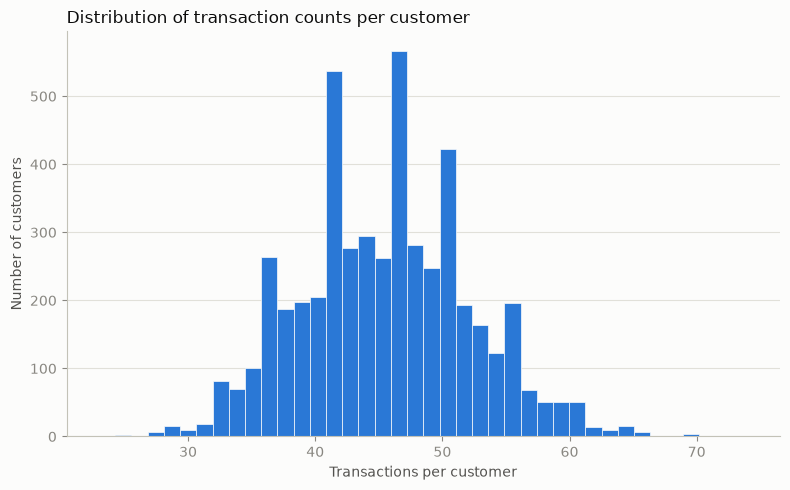

In [12]:
import matplotlib.pyplot as plt

txns_per_user = combined_df.groupby('user_id').size().rename('n_transactions')

print(txns_per_user.describe())
print('\nPercentiles:')
print(txns_per_user.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]))

fig, ax = plt.subplots(figsize=(8, 5))
ax.set_facecolor('#fcfcfb')
fig.patch.set_facecolor('#fcfcfb')

ax.hist(txns_per_user, bins=40, color='#2a78d6', edgecolor='#fcfcfb', linewidth=0.5)

ax.set_xlabel('Transactions per customer', color='#52514e')
ax.set_ylabel('Number of customers', color='#52514e')
ax.set_title('Distribution of transaction counts per customer', color='#0b0b0b', loc='left')

ax.grid(axis='y', color='#e1e0d9', linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
for spine in ['left', 'bottom']:
    ax.spines[spine].set_color('#c3c2b7')
ax.tick_params(colors='#898781')

plt.tight_layout()
plt.show()

- customers have approximately 45 transactions.
- and the number of transactions are normally distributed.

Customers with at least one fraudulent transaction: 2233 / 5000 (44.66%)

Distribution of fraud COUNT per customer:
count    5000.000000
mean        0.598000
std         0.776735
min         0.000000
25%         0.000000
50%         0.000000
75%         1.000000
max         5.000000
Name: n_fraud, dtype: float64
n_fraud
0    2767
1    1608
2     509
3     102
4      12
5       2
Name: count, dtype: int64

Distribution of fraud RATE per customer (fraud txns / total txns):
count    5000.000000
mean        0.016403
std         0.021377
min         0.000000
25%         0.000000
50%         0.000000
75%         0.028571
max         0.160000
Name: fraud_rate, dtype: float64
0.05    0.022222
0.25    0.025641
0.50    0.029412
0.75    0.044444
0.95    0.071429
0.99    0.090909
Name: fraud_rate, dtype: float64


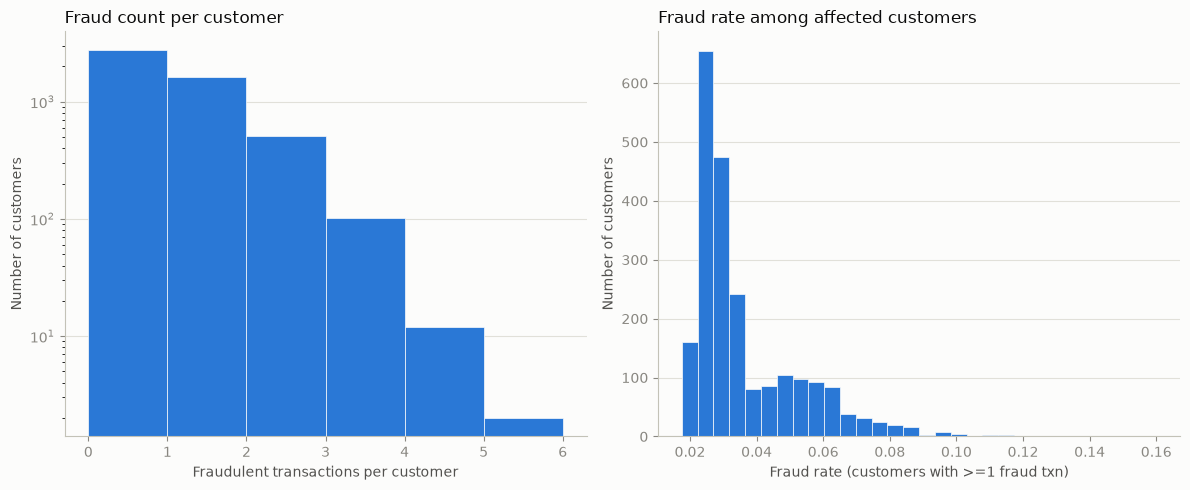

In [13]:
fraud_per_user = train_df.groupby('user_id')['label'].agg(
    n_transactions='size',
    n_fraud='sum',
)
fraud_per_user['fraud_rate'] = fraud_per_user['n_fraud'] / fraud_per_user['n_transactions']

print('Customers with at least one fraudulent transaction:',
      (fraud_per_user['n_fraud'] > 0).sum(), '/', len(fraud_per_user),
      '({:.2f}%)'.format(100 * (fraud_per_user['n_fraud'] > 0).mean()))

print('\nDistribution of fraud COUNT per customer:')
print(fraud_per_user['n_fraud'].describe())
print(fraud_per_user['n_fraud'].value_counts().sort_index())

print('\nDistribution of fraud RATE per customer (fraud txns / total txns):')
print(fraud_per_user['fraud_rate'].describe())
print(fraud_per_user.loc[fraud_per_user['n_fraud'] > 0, 'fraud_rate'].quantile(
    [0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax in axes:
    ax.set_facecolor('#fcfcfb')
fig.patch.set_facecolor('#fcfcfb')

max_fraud = fraud_per_user['n_fraud'].max()
axes[0].hist(
    fraud_per_user['n_fraud'],
    bins=range(0, max_fraud + 2),
    color='#2a78d6',
    edgecolor='#fcfcfb',
    linewidth=0.5,
)
axes[0].set_xlabel('Fraudulent transactions per customer', color='#52514e')
axes[0].set_ylabel('Number of customers', color='#52514e')
axes[0].set_title('Fraud count per customer', color='#0b0b0b', loc='left')
axes[0].set_yscale('log')

fraud_only = fraud_per_user.loc[fraud_per_user['n_fraud'] > 0, 'fraud_rate']
axes[1].hist(fraud_only, bins=30, color='#2a78d6', edgecolor='#fcfcfb', linewidth=0.5)
axes[1].set_xlabel('Fraud rate (customers with >=1 fraud txn)', color='#52514e')
axes[1].set_ylabel('Number of customers', color='#52514e')
axes[1].set_title('Fraud rate among affected customers', color='#0b0b0b', loc='left')

for ax in axes:
    ax.grid(axis='y', color='#e1e0d9', linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_color('#c3c2b7')
    ax.tick_params(colors='#898781')

plt.tight_layout()
plt.show()

# Univariate Analysis


amount — overall
count    182125.000000
mean         27.295336
std          24.978242
min           0.364086
25%          11.930504
50%          20.066676
75%          33.997392
max         639.898059

amount — by label
          count       mean        std       min        25%        50%        75%         max
label                                                                                       
0      179135.0  27.257979  24.887860  0.364086  11.928504  20.061662  33.950062  639.898059
1        2990.0  29.533426  29.818386  1.441696  12.033168  20.414823  37.063179  443.614981

amount — tail quantiles
          overall     label=0     label=1
0.950   72.860411   72.714645   82.653269
0.990  124.500800  124.199028  139.080221
0.999  224.658800  224.161162  293.672040


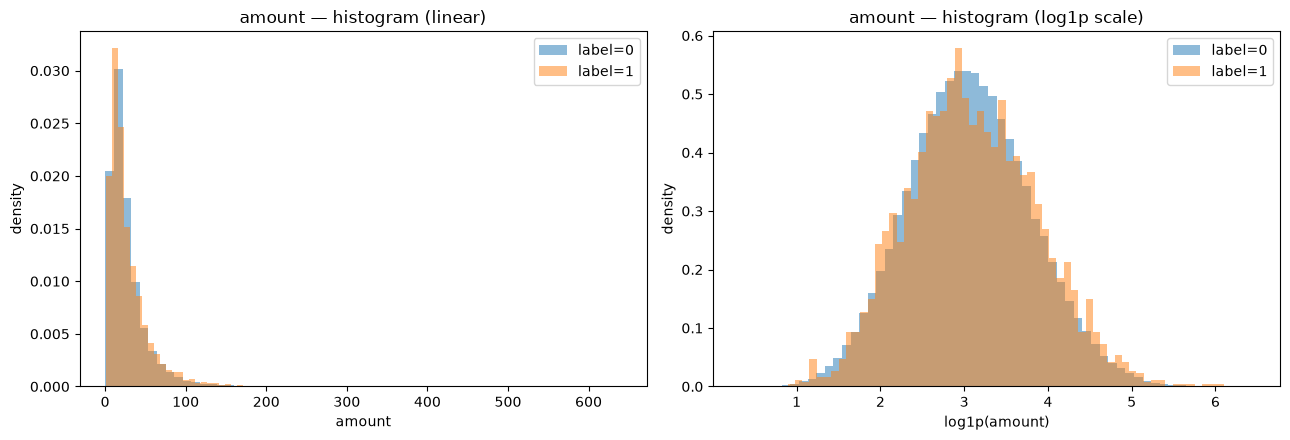


hours_since_prev_txn — overall
count    182125.000000
mean      55256.849301
std       56550.922597
min           0.000000
25%       15138.000000
50%       37793.000000
75%       76965.000000
max      869794.000000

hours_since_prev_txn — by label
          count          mean           std   min      25%      50%      75%       max
label                                                                                 
0      179135.0  55247.477310  56541.870713   0.0  15128.5  37787.0  76973.5  869794.0
1        2990.0  55818.338127  57097.353277  11.0  15714.0  38314.5  76546.0  414416.0

hours_since_prev_txn — tail quantiles
         overall    label=0     label=1
0.950  168114.00  168022.30  171858.250
0.990  258421.44  258326.14  266700.510
0.999  394372.94  394372.29  381387.259


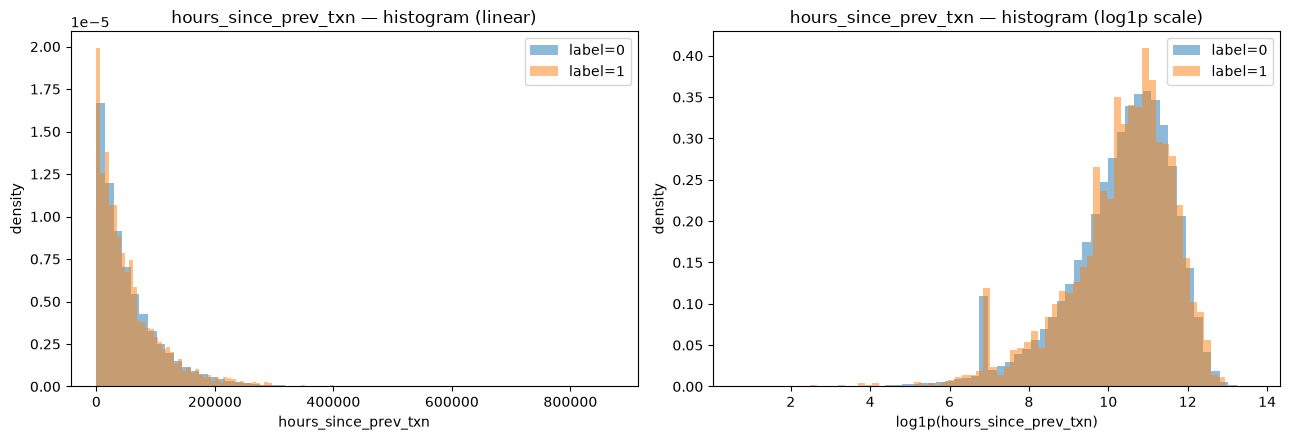


merchant_category (20 distinct values)
                   count  freq_pct  fraud_rate_pct
merchant_category                                 
0                  10280      5.64           1.586
1                   8354      4.59           1.676
2                   8985      4.93           1.736
3                   9133      5.01           1.708
4                   9860      5.41           1.511
5                   8869      4.87           1.657
6                   8893      4.88           1.732
7                   9401      5.16           1.659
8                   9204      5.05           1.738
9                   8372      4.60           1.613
10                  8933      4.90           1.567
11                  9309      5.11           1.579
12                  8661      4.76           1.674
13                  9652      5.30           1.720
14                  9506      5.22           1.536
15                  9208      5.06           1.640
16                  8532      4.68        

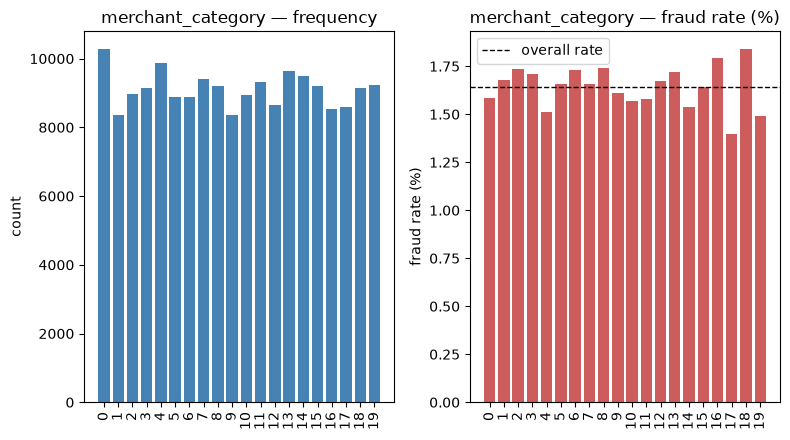


country (30 distinct values)
         count  freq_pct  fraud_rate_pct
country                                 
0         5687      3.12           1.653
1         6097      3.35           1.624
2         6061      3.33           1.782
3         6653      3.65           1.503
4         6161      3.38           1.720
5         6102      3.35           1.573
6         6249      3.43           1.664
7         6014      3.30           1.779
8         6848      3.76           1.825
9         6197      3.40           1.420
10        5645      3.10           1.771
11        5851      3.21           1.521
12        5953      3.27           1.478
13        6584      3.62           1.321
14        5990      3.29           1.636
15        6552      3.60           1.740
16        6453      3.54           1.844
17        5413      2.97           1.607
18        6169      3.39           1.621
19        6154      3.38           1.544
20        5847      3.21           1.539
21        5649      3.10   

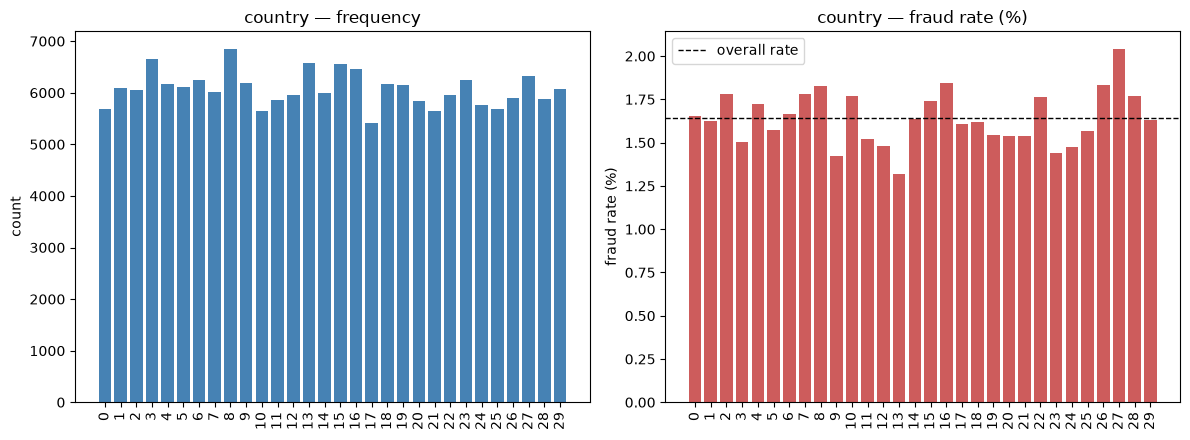


channel (2 distinct values)
          count  freq_pct  fraud_rate_pct
channel                                  
0        127602     70.06           1.650
1         54523     29.94           1.621


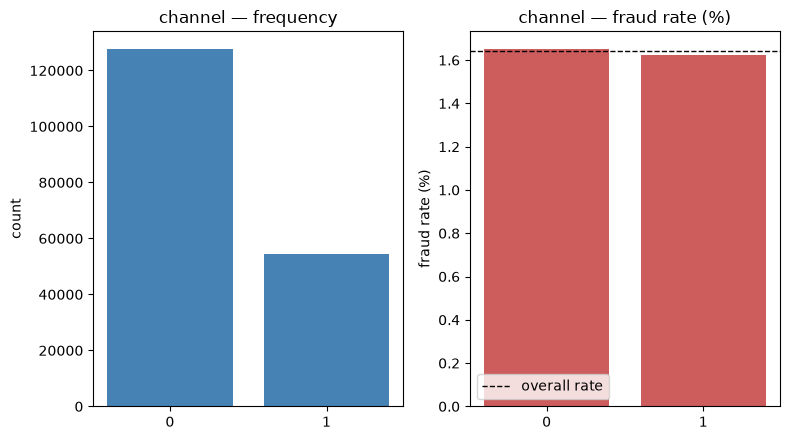

In [3]:
%run univariate_analysis.py

is_short_gap_since_prev
  rows 182,125   missing 0.0%   distinct 2
  base fraud rate 1.642%   AUC 0.5005 (|AUC-0.5| = 0.0005)   IV 0.0000


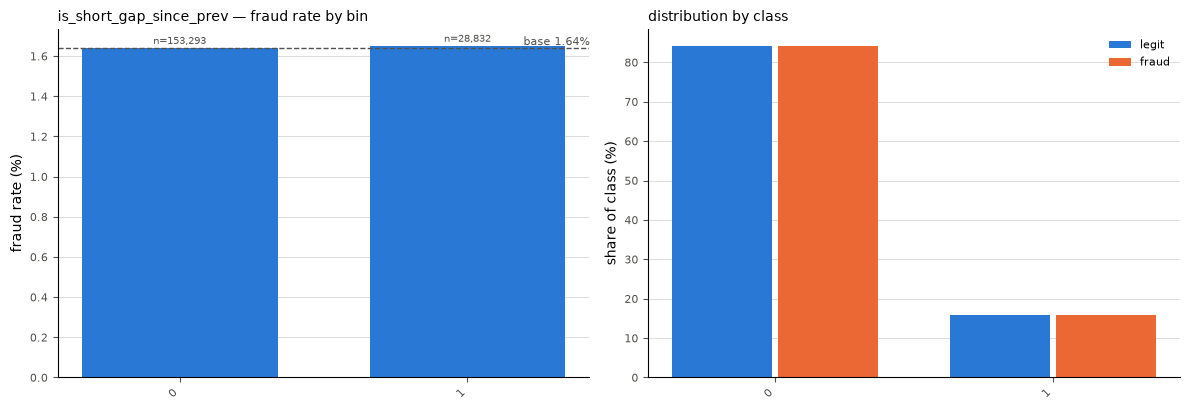

In [8]:
import sys; sys.path.insert(0, "..")     # once per kernel

from src.features.analysis import univariate, univariate_summary, all_feature_funcs
from src.features import build_features as bf

df = bf.load_combined()
table = univariate(df, bf.is_short_gap_since_prev)
